# Convolutional Architectures Lab

This lab explores three influential convolutional neural network (CNN) architectures:

1. [AlexNet](https://papers.nips.cc/paper/2012/file/c399862d3b9d6b76c8436e924a68c45b-Paper.pdf): A deep CNN that significantly improved image classification performance.
2. [VGG](https://arxiv.org/abs/1409.1556): Known for its simplicity and depth, using small, uniform convolutional filters.
3. [ResNet](https://arxiv.org/abs/1512.03385): Introduced residual connections, allowing for much deeper networks and addressing the vanishing gradient problem.

You will implement these architectures and apply them to the [OrganSMNIST](https://medmnist.com/) dataset from the MedMNIST collection: 28x28 grayscale CT slices of 11 abdominal organs. This hands-on experience will help you understand the design principles and performance characteristics of each architecture.

The lab begins with data loading and preprocessing, as shown in the code below. You'll then proceed to implement and train each model, comparing their performance on the organ classification task.

First, implement the training loop in `cm2003/train.py` (the parts marked `---CODE START HERE---`). You will use it for every model in this lab.

In [1]:
import torch


In [2]:
print(torch.version.cuda)

12.6


In [3]:
%load_ext autoreload
%autoreload 2
# autoreload re-imports the files in cm2003/ when you change them, so you do not need to restart
# the kernel after editing train.py or the models.

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms.v2 as v2
import matplotlib.pyplot as plt
import numpy as np

from cm2003.train import train, check_accuracy
from cm2003.plotting import plot_results

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')  # Apple-silicon Mac
else:
    device = torch.device('cpu')
print('using device:', device)

using device: cuda


In [6]:
torch.cuda.is_available()

False

In [6]:
from medmnist import OrganSMNIST

# Mean and standard deviation of the OrganSMNIST training images (pixel values in [0, 1])
MEAN, STD = 0.4953, 0.2826

transform = v2.Compose([
    v2.ToImage(),                           # PIL image -> tensor of shape (1, 28, 28)
    v2.ToDtype(torch.float32, scale=True),  # uint8 [0, 255] -> float [0, 1]
    v2.Normalize((MEAN,), (STD,)),
])

dataset_train = OrganSMNIST(root='./cm2003/datasets', split='train', transform=transform, download=True)
loader_train = DataLoader(dataset_train, batch_size=64, shuffle=True)

dataset_val = OrganSMNIST(root='cm2003/datasets', split='val', transform=transform, download=True)
loader_val = DataLoader(dataset_val, batch_size=64, shuffle=False)

dataset_test = OrganSMNIST(root='cm2003/datasets', split='test', transform=transform, download=True)
loader_test = DataLoader(dataset_test, batch_size=64, shuffle=False)

CLASS_NAMES = dataset_train.info['label']
print(len(dataset_train), 'training,', len(dataset_val), 'validation and', len(dataset_test), 'test images')
print('Classes:', CLASS_NAMES)

100%|██████████| 16.5M/16.5M [00:04<00:00, 3.60MB/s]


13932 training, 2452 validation and 8827 test images
Classes: {'0': 'bladder', '1': 'femur-left', '2': 'femur-right', '3': 'heart', '4': 'kidney-left', '5': 'kidney-right', '6': 'liver', '7': 'lung-left', '8': 'lung-right', '9': 'pancreas', '10': 'spleen'}


Image shape: torch.Size([1, 28, 28])


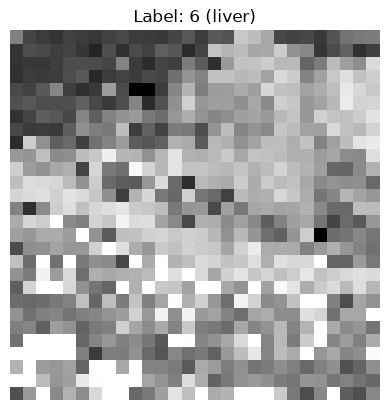

In [7]:
# See an image from the training set
image, label = dataset_train[5]
print(f"Image shape: {image.shape}")
plt.imshow(image.squeeze().numpy(), cmap='gray')
plt.title(f'Label: {label.item()} ({CLASS_NAMES[str(label.item())]})')
plt.axis('off')
plt.show()

## AlexNet Implementation

AlexNet, introduced in 2012, was a groundbreaking convolutional neural network architecture that significantly improved image classification performance. It consists of 5 convolutional layers followed by 3 fully connected layers. Key features include:

1. ReLU activations for faster training
2. Local Response Normalization (LRN) for improved generalization
3. Overlapping max pooling to reduce overfitting
4. Data augmentation and dropout for regularization
5. Training on GPUs, which made such a large network practical

The version you will implement is a much smaller network in the same spirit (three convolutional layers), since our images are only 28x28.

Your task is to implement AlexNet using PyTorch, adapting it for the OrganSMNIST dataset. Note that you may need to modify the original architecture slightly to accommodate the different input size of the OrganSMNIST images (28x28) compared to ImageNet (224x224). Please follow the instructions in the cm2003/models/alexnet.py file and run the cell below to load and test the model.

In [ ]:
import cm2003.models.alexnet as alexnet

model = alexnet.AlexNet(num_classes=11, in_channels=1)

def test_shape(model):
    x = torch.randn(16, 1, 28, 28)
    assert model(x).shape == (16, 11)
    print("Test passed")

test_shape(model)

## Training AlexNet

Now that you have implemented the AlexNet architecture, follow these steps to set up the training process:

1. Define the loss function and optimizer:
   - Choose an appropriate loss function (e.g., CrossEntropyLoss)
   - Select an optimizer (e.g., Adam) and set the learning rate

2. Create a training loop:
   - Iterate through a specified number of epochs
   - For each batch in the training data:
     - Move data to the appropriate device (CPU/GPU)
     - Perform forward pass, calculate loss, and backpropagate
     - Update model parameters
   - Print training progress at regular intervals

3. Implement a validation function:
   - Create a function to evaluate the model's performance on a given dataset
   - Calculate and return the accuracy

4. Train the model and monitor performance:
   - Run the training loop
   - After each epoch, evaluate the model on the validation set
   - Track and plot training loss and validation accuracy over time

5. Test the model:
   - Evaluate the trained model on the test set
   - Report the final test accuracy

Remember to move your model to the appropriate device (CPU or GPU) before training.

Experiment with different hyperparameters such as learning rate, batch size, and number of epochs to improve the model's performance.

If you have not done so yet, fill in the remaining code in `cm2003/train.py`, then run the cell below to train the model. You should expect to see a test accuracy of about 75 % (the validation accuracy will be higher, around 85 %: the OrganSMNIST test set comes from different CT scans and is harder).

For reference: there are 11 classes and the largest one is about 24% of the test set, so always predicting that class would give 24% accuracy.

In [ ]:
model = alexnet.AlexNet(num_classes=11, in_channels=1)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results = train(model, loader_train, loader_val, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

In [ ]:
# Plot the loss curves and validation accuracy
plot_results(results, title='AlexNet')

## VGG Implementation

VGG, introduced in 2014, is known for its simplicity and depth, using small, uniform convolutional filters. Its most common versions have 13 or 16 convolutional layers followed by 3 fully connected layers (VGG16 and VGG19, counting the fully connected layers). You will implement VGG13 (10 convolutional layers in the original; a shorter version with 8 here, since our images are small). Key features include:

1. Small, uniform convolutional filters (3x3)
2. Max pooling for downsampling
3. Dropout for regularization
4. Data augmentation

Follow the instructions in the cm2003/models/vgg.py file and run the cell below to load and test the model.

In [ ]:
import cm2003.models.vgg as vgg

model = vgg.VGG13(num_classes=11, in_channels=1)

def test_shape(model):
    x = torch.randn(16, 1, 28, 28)
    assert model(x).shape == (16, 11)
    print("Test passed")

test_shape(model)

In [ ]:
model = vgg.VGG13(num_classes=11, in_channels=1)

#TODO Define loss function and optimizer
criterion = None
optimizer = None

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results = train(model, loader_train, loader_val, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

In [ ]:
# Plot the results
plot_results(results, title='VGG13')

## Question
What is the difference between AlexNet and VGG in the training results? Can you explain these results in terms of the architectures?

## Add regularization
Re-run the training of VGG with stronger regularization and compare the curves with the run above:

- **Dropout:** the VGG classifier already has dropout. Think carefully about where else dropout could help and try it, e.g. `nn.Dropout2d` in the convolutional blocks or a different dropout probability. For this you need to modify `cm2003/models/vgg.py` (for example by adding a `dropout` argument to `VGG13`, so the model above still works).
- **L2 regularization (weight decay):** set the `weight_decay` argument of the optimizer. Note that with Adam, `weight_decay` is added to the gradient and is then rescaled by Adam's adaptive learning rates, which weakens it; `torch.optim.AdamW` applies the decay directly to the weights ("decoupled weight decay") and is the usual choice today.

In [ ]:
# Training code below with dropout and L2 regularization

# plot_results([results_vgg, results_vgg_reg], labels=['VGG13', 'VGG13 + regularization'])

## ResNet Implementation

ResNet, introduced in 2015, uses residual (skip) connections, allowing for much deeper networks and addressing the vanishing gradient problem. It consists of convolutional layers with residual connections. Key features include:

1. Residual connections, which let gradients flow directly through the network so that very deep networks can be trained
2. Batch normalization for faster and more stable training
3. Bottleneck blocks (1x1, 3x3, 1x1 convolutions) in the deeper versions such as ResNet-50, which you will implement


Follow the instructions in the cm2003/models/resnet.py file and run the cell below to load and test the model.

In [ ]:
import cm2003.models.resnet as resnet

model = resnet.ResNet50(num_classes=11, in_channels=1)

def test_shape(model):
    x = torch.randn(16, 1, 28, 28)
    assert model(x).shape == (16, 11)
    print("Test passed")

test_shape(model)

## Training ResNet

Now that you have implemented the ResNet architecture, follow these steps to set up the training process:

1. Define the loss function and optimizer:
   - Choose an appropriate loss function (e.g., CrossEntropyLoss)
   - Select an optimizer (e.g., Adam) and set the learning rate

2. Create a training loop:
   - Iterate through a specified number of epochs

You should expect to see a test accuracy of about 74 %.

In [ ]:
# Training code below
model = resnet.ResNet50(num_classes=11, in_channels=1)

#TODO Define loss function and optimizer
criterion = None 
optimizer = None

model.to(device)

# Set number of epochs
num_epochs = 10


# Train the model
model, results = train(model, loader_train, loader_val, criterion, optimizer, device, num_epochs)

# Check accuracy on the test set
test_loss, test_accuracy = check_accuracy(model, loader_test, criterion, device)
train_loss, train_accuracy = check_accuracy(model, loader_train, criterion, device)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}")

In [ ]:
# TODO: plot the loss curves and validation accuracy (you can use plot_results)

## Question
What are some possible issues with the training process of the ResNet? Hint: compare the number of parameters of the three models (`sum(p.numel() for p in model.parameters())`) with the size of the training set, and look at the size of the feature maps after each stage for a 28x28 input.